# XGBoost: raw vs engineered features

This notebook trains XGBoost on `data/processed/features_v1.parquet` (made by `notebooks/feature_engineering.ipynb`)
and checks how much the engineered features add on top of the raw columns.

What it does:

1. Sets up the splits from `Context.md`: 80/10/10 by time, with expanding-window CV inside the training block.
2. Builds the feature sets to compare (raw → + row-level features → + customer history → + frequency).
3. **Experiment 1, ladder:** adds one kind of feature at a time.
4. **Experiment 2, leave-one-family-out:** removes one engineered family at a time from the full set.
5. **Experiment 3, V columns:** all V columns vs the proposed pruned list vs none.
6. Light hyperparameter tuning on the best set.
7. Refits the chosen model on the whole training block and scores the validation block.
8. Looks at which features the model relies on.

Rules:

- All comparing and tuning uses CV inside the training block. The validation block is only used once a choice
  has been made, for early stopping of the final model and for picking the threshold.
- The test block is never touched here. It gets scored once, after the group's experiment freeze.
- Every run appends one row per fold to `results/log.csv`. That's the only file this notebook writes. Tables in
  the summary are read back from the log, so they only show numbers that are in it.
- If the notebook stops halfway (or you re-run it), runs already in the log are skipped, so nothing is redone.

Rough run time on a laptop: 10 to 150 s per fit depending on fold size and trees used. The ladder, ablation and
V experiments took about 2 hours; tuning (20 configs x 4 folds) adds roughly 1.5 to 2.5 hours. Those first three
experiments were run with a 3000-tree cap; tuning and later runs use 5000 (stored as `max_trees` in the log). The switches in the next cell turn the longer experiments on or off.

In [1]:
import json
import time
import csv
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

SPEC_PATH = ROOT / "config" / "features_v1.yaml"
V_PROPOSAL_PATH = ROOT / "config" / "features.yaml"
LOG_PATH = ROOT / "results" / "log.csv"
AUTHOR = "Mabel"
MODEL = "xgboost"

N_TRAIN, N_VAL = 472_432, 59_054      # Context.md: first 80% train, next 10% validation, last 10% test
SEEDS = [0, 1, 2]

# Switches for the longer parts
RUN_LADDER_ALL_SEEDS = True           # ladder with seeds 0, 1, 2 (otherwise seed 0 only)
RUN_ABLATION = True                   # 9 leave-one-family-out sets, seed 0
RUN_V_VARIANTS = True                 # all V / no V, seed 0
RUN_TUNING = True                     # random search on the best set, seed 0
N_TUNING_CONFIGS = 20
BEST_SET_OVERRIDE = None              # e.g. "S3_all" to skip automatic choice of the set to tune

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # fixed order: one colour per feature set
GREY = "#8a8985"
print("xgboost", xgb.__version__)

xgboost 3.4.1


## 1. Load the feature table

The parquet already contains the raw columns plus the engineered `fe_` columns, in time order. The YAML file next
to it lists which columns are features, which are identifiers, and which engineered family each column belongs to.

In [2]:
spec = yaml.safe_load(open(SPEC_PATH))
full = pd.read_parquet(ROOT / spec["parquet"])
assert full["TransactionDT"].is_monotonic_increasing, "table must stay in time order"
assert len(full) == 590_540

y = full[spec["target"]].to_numpy()
day = full["TransactionDay"].to_numpy()
uid = full["uid"].astype(str).to_numpy()
NOT_FEATURES = set(spec["not_features"]) | {spec["target"]}
print(f"{full.shape[0]:,} rows x {full.shape[1]} columns")

590,540 rows x 510 columns


## 2. Splits

**Outer split (80/10/10 by row position).** The training block is used for all comparisons and tuning. The
validation block is used once at the end. The test block is left alone.

**CV inside the training block.** Expanding-window walk-forward folds, as in `Context.md`: training rows are put in
30-day bins counted from the first day, and fold k trains on bins 0 to k−1 and validates on bin k. That gives 4
folds. Each validation month is always later than everything the model trained on, which is what happens when a
real model is deployed.

**Early stopping.** XGBoost needs a held-out set to decide when to stop adding trees. Inside each fold we use the
last 10% (by time) of the fold's training rows for this, so the fold's validation month is never used to tune
anything. The final model uses the validation block for early stopping, as `Context.md` describes.

The table shows each fold's size and fraud rate, plus how many validation rows come from a customer (uid) already
seen in that fold's training data.

In [3]:
train_idx = np.arange(N_TRAIN)
val_idx = np.arange(N_TRAIN, N_TRAIN + N_VAL)
test_idx = np.arange(N_TRAIN + N_VAL, len(full))          # defined only so we can assert it's never used
assert len(test_idx) == 59_054

bins = (day[:N_TRAIN] - day[:N_TRAIN].min()) // 30
FOLDS = [(np.where(bins < k)[0], np.where(bins == k)[0]) for k in range(1, bins.max() + 1)]

def early_stop_split(idx, frac=0.1):
    # last `frac` of the rows (by time) is held out for early stopping
    cut = int(len(idx) * (1 - frac))
    return idx[:cut], idx[cut:]

def seen_share(va, tr):
    # share of rows in `va` whose uid also appears in `tr` (hash lookup, fast)
    return pd.Series(uid[va]).isin(uid[tr]).mean()

rows = []
for k, (tr, va) in enumerate(FOLDS, 1):
    rows.append({"fold": k, "train days": f"{day[tr].min()}-{day[tr].max()}", "train rows": len(tr),
                 "train fraud rate": y[tr].mean(), "val days": f"{day[va].min()}-{day[va].max()}",
                 "val rows": len(va), "val fraud rate": y[va].mean(),
                 "val rows from seen uid": seen_share(va, tr)})
rows.append({"fold": "holdout", "train days": f"{day[train_idx].min()}-{day[train_idx].max()}",
             "train rows": N_TRAIN, "train fraud rate": y[train_idx].mean(),
             "val days": f"{day[val_idx].min()}-{day[val_idx].max()}", "val rows": N_VAL,
             "val fraud rate": y[val_idx].mean(),
             "val rows from seen uid": seen_share(val_idx, train_idx)})
pd.DataFrame(rows).set_index("fold").round(4)

,train days,train rows,train fraud rate,val days,val rows,val fraud rate,val rows from seen uid
fold,,,,,,,
1,1-30,134339,0.0253,31-60,89399,0.0400,0.3579
2,1-60,223738,0.0312,61-90,92189,0.0404,0.3910
3,1-90,315927,0.0339,91-120,98615,0.0395,0.3932
4,1-120,414542,0.0352,121-141,57890,0.0345,0.4885
holdout,1-141,472432,0.0351,141-161,59054,0.0313,0.4857


## 3. Feature sets

The engineered features are split by what information they need, because that's the comparison that matters for
RQ3 ("is a user profile enough?"):

- **Row-level:** only use the transaction itself (amount patterns, hour, normalised D columns, parsed
  device/email/browser info, card and country flags, missing-value counts).
- **Customer history:** use the same customer's (or card's, or device's) earlier transactions. These are the
  novelty and velocity families plus every `fe_uid_` feature.
- **Frequency:** how common a value has been among everyone's earlier transactions.

| Set | Contents |
| --- | --- |
| `S0_raw` | raw columns, with the proposed pruned V list (229 of 339 V columns) |
| `S1_row` | S0 + row-level features |
| `S2_history` | S1 + customer-history features |
| `S3_all` | S2 + frequency features |
| `S3_minus_<family>` | S3 without one engineered family (for Experiment 2) |
| `S3_allV`, `S3_noV` | S3 with all 339 V columns, or none (for Experiment 3) |

`TransactionID`, `TransactionDT`, `TransactionDay` and `uid` are never features. Raw time would only teach the
model "what period is this", which doesn't carry over to later months, and the raw uid would let it memorise
customers.

The V pruning list is still a proposal waiting for the group's approval, so `S3_allV` doubles as a check on
whether pruning costs anything.

In [4]:
raw_cols = spec["raw_feature_cols"]
fams = spec["engineered_cols"]
all_v = [c for c in raw_cols if c.startswith("V") and c[1:].isdigit()]
kept_v = set(yaml.safe_load(open(V_PROPOSAL_PATH))["v_columns_proposed"]["keep"])
raw_non_v = [c for c in raw_cols if c not in all_v]
raw_pruned = raw_non_v + [c for c in all_v if c in kept_v]

eng = [c for cols in fams.values() for c in cols]
history = [c for c in eng if c in fams["novelty"] or c in fams["velocity"] or c.startswith("fe_uid_")]
frequency = list(fams["frequency"])
row_level = [c for c in eng if c not in history and c not in frequency]

FEATURE_SETS = {
    "S0_raw": raw_pruned,
    "S1_row": raw_pruned + row_level,
    "S2_history": raw_pruned + row_level + history,
    "S3_all": raw_pruned + eng,
}
for fam, cols in fams.items():
    FEATURE_SETS[f"S3_minus_{fam}"] = [c for c in FEATURE_SETS["S3_all"] if c not in set(cols)]
FEATURE_SETS["S3_allV"] = raw_cols + eng
FEATURE_SETS["S3_noV"] = raw_non_v + eng
LADDER = ["S0_raw", "S1_row", "S2_history", "S3_all"]

for name, cols in FEATURE_SETS.items():
    assert not NOT_FEATURES & set(cols), f"{name} contains an identifier or the target"
    assert len(cols) == len(set(cols)), f"{name} has duplicate columns"

print(f"row-level: {len(row_level)}, customer history: {len(history)}, frequency: {len(frequency)}")
pd.Series({k: len(v) for k, v in FEATURE_SETS.items()}, name="n_features").to_frame()

row-level: 35, customer history: 32, frequency: 6


,n_features
S0_raw,322
S1_row,357
S2_history,389
S3_all,395
S3_minus_amount,389
S3_minus_time,391
S3_minus_d_norm,391
S3_minus_novelty,380
S3_minus_velocity,383
S3_minus_identity,380


## 4. Model, metrics and logging

**Starting config.** One reasonable XGBoost config is used for every comparison, so differences between feature
sets come from the features and not from tuning luck. It is tuned only at the end, on the winning set.

| Setting | Value | Why |
| --- | --- | --- |
| `tree_method` | `hist` | fast on 470k rows; also needed for native categorical support |
| `max_depth` | 8 | deep enough for interactions (e.g. product × device) without growing huge trees |
| `learning_rate` | 0.05 | small steps; early stopping picks the number of trees |
| `subsample`, `colsample_bytree` | 0.8, 0.5 | randomness against overfitting; 0.5 helps with ~500 partly redundant columns |
| `scale_pos_weight` | negatives / positives in the training rows | fraud is ~3.5%; this stops the model ignoring it. Computed from each fold's own training rows. |
| `eval_metric` | `aucpr` | early stopping on the same metric we report |
| early stopping | 100 rounds, max 3000 trees | |

Category columns (email domains, device info, the new `fe_` categories, etc.) are passed as pandas categories and
XGBoost handles them natively (`enable_categorical=True`). NaN is left as NaN, since XGBoost learns which way
missing values should go.

**Metrics** (from `Context.md`): PR-AUC is the main one (a random model scores about 0.035). AUROC and recall in
the top 1% of scores are also logged. Precision and recall need a threshold, so they are only reported for the
final model on the validation block.

**Logging.** One row per fold per run in `results/log.csv`, with the columns from `Context.md`. The `params` column
holds a JSON with the fold, settings, number of features and a `run_key`, which is how finished runs are skipped
when the notebook is re-run.

In [5]:
BASE_HP = {"max_depth": 8, "learning_rate": 0.05, "subsample": 0.8, "colsample_bytree": 0.5,
           "min_child_weight": 1, "reg_lambda": 1.0, "spw": "ratio"}
MAX_TREES, EARLY_STOP = 5000, 100      # ladder/ablation/V rows in the log were run with a 3000 cap

def spw_value(mode, y_fit):
    ratio = (y_fit == 0).sum() / max((y_fit == 1).sum(), 1)
    return {"ratio": ratio, "sqrt": float(np.sqrt(ratio)), "none": 1.0}[mode]

def fit_xgb(cols, fit_idx, es_idx, hp, seed):
    X = full[cols]
    y_fit = y[fit_idx]
    params = {"objective": "binary:logistic", "eval_metric": "aucpr", "tree_method": "hist",
              "max_depth": int(hp["max_depth"]), "learning_rate": hp["learning_rate"], "subsample": hp["subsample"],
              "colsample_bytree": hp["colsample_bytree"], "min_child_weight": hp["min_child_weight"],
              "reg_lambda": hp["reg_lambda"], "scale_pos_weight": spw_value(hp["spw"], y_fit),
              "seed": seed, "nthread": -1, "verbosity": 0}
    dfit = xgb.QuantileDMatrix(X.iloc[fit_idx], y_fit, enable_categorical=True)
    des = xgb.QuantileDMatrix(X.iloc[es_idx], y[es_idx], ref=dfit, enable_categorical=True)
    booster = xgb.train(params, dfit, MAX_TREES, evals=[(des, "es")],
                        early_stopping_rounds=EARLY_STOP, verbose_eval=False)
    return booster

def predict(booster, cols, idx):
    d = xgb.DMatrix(full[cols].iloc[idx], enable_categorical=True)
    return booster.predict(d, iteration_range=(0, booster.best_iteration + 1))

def recall_top1pct(y_true, score):
    k = int(np.ceil(0.01 * len(score)))
    top = np.argsort(-score, kind="stable")[:k]
    return y_true[top].sum() / y_true.sum()

def evaluate(y_true, score, threshold=None):
    out = {"pr_auc": average_precision_score(y_true, score), "auroc": roc_auc_score(y_true, score),
           "recall_top1pct": recall_top1pct(y_true, score), "precision": None, "recall": None}
    if threshold is not None:
        pred = score >= threshold
        out["precision"] = y_true[pred].mean() if pred.any() else 0.0
        out["recall"] = pred[y_true == 1].mean()
    return out

def pick_threshold(y_true, score):
    # threshold that maximises F1 on the given data
    p, r, t = precision_recall_curve(y_true, score)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.argmax(f1)])

In [6]:
LOG_COLS = ["date", "author", "model", "feature_set", "cv_scheme", "split", "seed", "params",
            "pr_auc", "auroc", "precision", "recall", "recall_top1pct", "runtime_s"]

def log_run(row):
    LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
    new = not LOG_PATH.exists() or LOG_PATH.stat().st_size == 0
    if not new:
        with open(LOG_PATH) as f:
            header = next(csv.reader(f))
        assert header == LOG_COLS, f"results/log.csv has unexpected columns: {header}"
    with open(LOG_PATH, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=LOG_COLS)
        if new:
            w.writeheader()
        w.writerow({k: row.get(k) for k in LOG_COLS})

def read_log():
    # this notebook's rows from results/log.csv, with the params JSON expanded into columns
    if not LOG_PATH.exists():
        return pd.DataFrame()
    log = pd.read_csv(LOG_PATH)
    log = log[(log["model"] == MODEL) & (log["author"] == AUTHOR)].copy()
    if log.empty:
        return log
    p = pd.json_normalize(log["params"].map(json.loads).tolist()).set_index(log.index)
    return log.join(p[[c for c in p.columns if c not in log.columns]])

def done_keys():
    log = read_log()
    return set(log["run_key"]) if "run_key" in log else set()

def run_cv(set_name, hp, seed, tag="base"):
    # walk-forward CV for one feature set / config / seed; logs one row per fold, skips folds already logged
    cols = FEATURE_SETS[set_name]
    done = done_keys()
    for k, (tr, va) in enumerate(FOLDS, 1):
        key = f"{tag}|{set_name}|fold{k}|seed{seed}"
        if key in done:
            continue
        t0 = time.time()
        fit_i, es_i = early_stop_split(tr)
        booster = fit_xgb(cols, fit_i, es_i, hp, seed)
        m = evaluate(y[va], predict(booster, cols, va))
        params = {"run_key": key, "tag": tag, "fold": k, "features": "features_v1", "n_features": len(cols),
                  "best_iteration": booster.best_iteration, "max_trees": MAX_TREES, **hp}
        log_run({"date": date.today().isoformat(), "author": AUTHOR, "model": MODEL, "feature_set": set_name,
                 "cv_scheme": "time", "split": "cv", "seed": seed, "params": json.dumps(params),
                 **m, "runtime_s": round(time.time() - t0, 1)})
        print(f"  {set_name:22s} {tag:8s} fold {k} seed {seed}: logged ({time.time() - t0:.0f}s)")

def cv_table(sets, tag="base", seeds=None):
    # mean and std of fold scores per feature set, read from the log
    log = read_log()
    log = log[(log["split"] == "cv") & (log["tag"] == tag) & log["feature_set"].isin(sets)]
    if seeds is not None:
        log = log[log["seed"].isin(seeds)]
    agg = log.groupby("feature_set").agg(
        pr_auc_mean=("pr_auc", "mean"), pr_auc_std=("pr_auc", "std"),
        auroc_mean=("auroc", "mean"), recall_top1pct_mean=("recall_top1pct", "mean"),
        n_runs=("pr_auc", "size"), avg_trees=("best_iteration", "mean"))
    per_fold = log.groupby(["feature_set", "fold"])["pr_auc"].mean().unstack().add_prefix("pr_auc fold ")
    return agg.join(per_fold).reindex([s for s in sets if s in agg.index]).round(4)

## 5. Experiment 1: the ladder

Each step adds one kind of information. Seed 0 runs first for all four sets, then seeds 1 and 2.

How to read it: a step is a real improvement only if it's bigger than the spread across folds, and it should show
up in most folds, not just on average. Fold 1 is trained on one month only (with a lower fraud rate than later
months), so it usually scores lowest for every set.

In [7]:
for seed in (SEEDS if RUN_LADDER_ALL_SEEDS else [0]):
    for s in LADDER:
        run_cv(s, BASE_HP, seed)
ladder = cv_table(LADDER)
ladder

,pr_auc_mean,pr_auc_std,auroc_mean,recall_top1pct_mean,n_runs,avg_trees,pr_auc fold 1.0,pr_auc fold 2.0,pr_auc fold 3.0,pr_auc fold 4.0
feature_set,,,,,,,,,,
S0_raw,0.5361,0.0323,0.8814,0.2398,12,1886.6667,0.5358,0.5571,0.4885,0.5628
S1_row,0.5559,0.0427,0.8799,0.2425,12,1855.5833,0.5304,0.5841,0.5040,0.6053
S2_history,0.5602,0.0340,0.8831,0.2433,12,1939.5000,0.5405,0.5787,0.5248,0.5967
S3_all,0.5712,0.0331,0.8865,0.2443,12,2250.4167,0.5500,0.5845,0.5363,0.6138


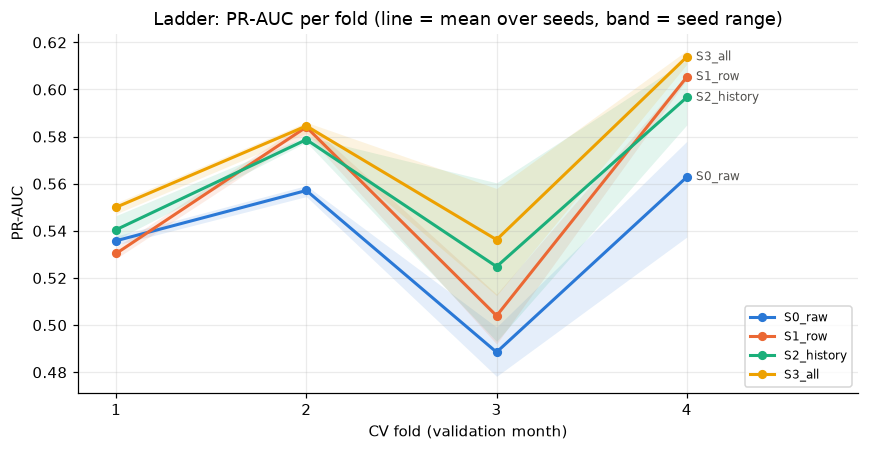

In [8]:
log = read_log()
lad = log[(log["split"] == "cv") & (log["tag"] == "base") & log["feature_set"].isin(LADDER)]
per_fold = lad.groupby(["feature_set", "fold"])["pr_auc"].agg(["mean", "min", "max"])

fig, ax = plt.subplots(figsize=(8, 4.2))
for color, s in zip(COLORS, LADDER):
    if s not in per_fold.index.get_level_values(0):
        continue
    d = per_fold.loc[s]
    ax.plot(d.index, d["mean"], color=color, lw=2, marker="o", ms=5, label=s)
    if lad["seed"].nunique() > 1:
        ax.fill_between(d.index, d["min"], d["max"], color=color, alpha=0.12, lw=0)
    ax.annotate(s, (d.index[-1], d["mean"].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color="#52514e")
ax.set_xticks(range(1, len(FOLDS) + 1))
ax.set_xlabel("CV fold (validation month)"); ax.set_ylabel("PR-AUC")
ax.set_title("Ladder: PR-AUC per fold (line = mean over seeds, band = seed range)")
ax.legend(fontsize=8, loc="lower right"); ax.set_xlim(0.8, len(FOLDS) + 0.9)
fig.tight_layout(); plt.show()

## 6. Experiment 2: leave one family out

Starting from `S3_all`, each run drops one engineered family. If PR-AUC falls when a family is removed, that family
carries information the others don't. If nothing changes, it's redundant (or just not useful). Seed 0 only.

The change is computed fold by fold against `S3_all` with the same seed, so differences between months cancel
out. The error bar is the spread of that change across folds.

In [9]:
ABLATION = [f"S3_minus_{f}" for f in fams]
if RUN_ABLATION:
    for s in ABLATION:
        run_cv(s, BASE_HP, seed=0)

log = read_log()
cv0 = log[(log["split"] == "cv") & (log["tag"] == "base") & (log["seed"] == 0)]
ref = cv0[cv0["feature_set"] == "S3_all"].set_index("fold")["pr_auc"]
rows = []
for s in ABLATION:
    d = cv0[cv0["feature_set"] == s].set_index("fold")["pr_auc"]
    if len(d) == len(FOLDS) and len(ref) == len(FOLDS):
        delta = d - ref
        rows.append({"family removed": s.replace("S3_minus_", ""), "n_features": len(FEATURE_SETS[s]),
                     "pr_auc_mean": d.mean(), "change_mean": delta.mean(), "change_std": delta.std(),
                     "folds_worse": int((delta < 0).sum())})
ablation = pd.DataFrame(rows).set_index("family removed").sort_values("change_mean").round(4) if rows else pd.DataFrame()
ablation

,n_features,pr_auc_mean,change_mean,change_std,folds_worse
family removed,,,,,
d_norm,391,0.5556,-0.0106,0.0130,2
frequency,389,0.5647,-0.0015,0.0084,2
identity,380,0.5664,0.0002,0.0169,3
geo_card,391,0.5666,0.0004,0.0069,1
time,391,0.5674,0.0012,0.0126,3
missing,388,0.5680,0.0018,0.0113,3
velocity,383,0.5709,0.0047,0.0303,3
novelty,380,0.5728,0.0066,0.0238,3
amount,389,0.5762,0.0100,0.0271,2


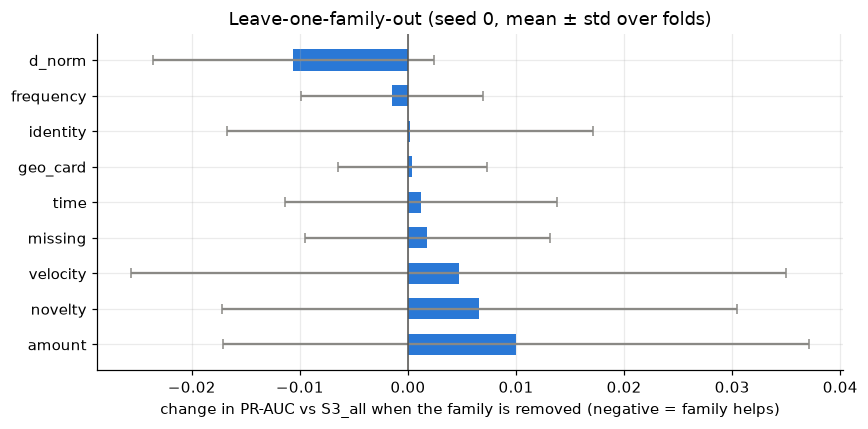

In [10]:
if len(ablation):
    fig, ax = plt.subplots(figsize=(8, 4))
    a = ablation.iloc[::-1]
    ax.barh(a.index, a["change_mean"], xerr=a["change_std"], color=COLORS[0], ecolor=GREY, capsize=3, height=0.6)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_xlabel("change in PR-AUC vs S3_all when the family is removed (negative = family helps)")
    ax.set_title("Leave-one-family-out (seed 0, mean ± std over folds)")
    fig.tight_layout(); plt.show()

## 7. Experiment 3: V columns

`S3_all` uses the proposed pruned V list. Here we compare it with keeping all 339 V columns and with dropping V
entirely. If dropping V costs little, a model built only on columns we can explain is a reasonable option; if
keeping all of them helps, the pruning threshold may be too aggressive.

In [11]:
V_SETS = ["S3_noV", "S3_all", "S3_allV"]
if RUN_V_VARIANTS:
    for s in ["S3_noV", "S3_allV"]:
        run_cv(s, BASE_HP, seed=0)
cv_table(V_SETS, seeds=[0]).assign(n_features=lambda d: [len(FEATURE_SETS[s]) for s in d.index])

,pr_auc_mean,pr_auc_std,auroc_mean,recall_top1pct_mean,n_runs,avg_trees,pr_auc fold 1.0,pr_auc fold 2.0,pr_auc fold 3.0,pr_auc fold 4.0,n_features
feature_set,,,,,,,,,,,
S3_noV,0.5578,0.0366,0.8837,0.2423,4,1873.25,0.5255,0.5807,0.5278,0.5973,166
S3_all,0.5662,0.0439,0.8877,0.2436,4,1972.50,0.5519,0.5861,0.5125,0.6142,395
S3_allV,0.5642,0.0372,0.8850,0.2444,4,1944.50,0.5484,0.5852,0.5200,0.6031,505


## 8. Light tuning on the best set

The set with the best mean CV PR-AUC in the ladder is tuned with a small random search (seed 0, same folds). Config
0 is the starting config, so the search can only match or beat it. The search space covers tree depth, learning
rate, minimum leaf weight, row and column sampling, L2 regularisation and how strongly fraud is up-weighted.

If tuning is switched off (or hasn't finished), the starting config is used for the validation block, and that
run is labelled `base`. Turning tuning on later adds a separate validation run for the tuned config; the old one
stays in the log.

Picking the best of 20 configs on the same 4 folds makes its CV score a bit optimistic. That's one reason the
validation block is checked afterwards.

In [12]:
lad = cv_table(LADDER)
BEST_SET = BEST_SET_OVERRIDE or lad["pr_auc_mean"].idxmax()
print("set to tune:", BEST_SET)

rng = np.random.default_rng(0)
SPACE = {"max_depth": [4, 6, 8, 10, 12], "learning_rate": [0.05, 0.1], "min_child_weight": [1, 3, 10, 30],
         "subsample": [0.7, 0.8, 1.0], "colsample_bytree": [0.3, 0.5, 0.7], "reg_lambda": [1.0, 5.0, 20.0],
         "spw": ["ratio", "sqrt", "none"]}
CONFIGS = [dict(BASE_HP)] + [{k: (v[rng.integers(len(v))]) for k, v in SPACE.items()}
                             for _ in range(N_TUNING_CONFIGS - 1)]
CONFIGS = [{k: (v.item() if hasattr(v, "item") else v) for k, v in c.items()} for c in CONFIGS]

if RUN_TUNING:
    for i, hp in enumerate(CONFIGS):
        run_cv(BEST_SET, hp, seed=0, tag=f"tune{i:02d}")

log = read_log()
tune = log[(log["split"] == "cv") & log["tag"].str.startswith("tune") & (log["feature_set"] == BEST_SET)]
hp_cols = list(SPACE)
tuning = (tune.groupby("tag").agg(pr_auc_mean=("pr_auc", "mean"), pr_auc_std=("pr_auc", "std"),
                                  n_folds=("pr_auc", "size"), avg_trees=("best_iteration", "mean"),
                                  **{c: (c, "first") for c in hp_cols})
          .sort_values("pr_auc_mean", ascending=False).round(4))
tuning = tuning[tuning["n_folds"] == len(FOLDS)]
# the tuned config is used only if the search has finished; otherwise the starting config
BEST_CONFIG = tuning.index[0] if len(tuning) else "base"
BEST_HP = {c: tuning.iloc[0][c] for c in hp_cols} if len(tuning) else dict(BASE_HP)
BEST_HP = {k: (v.item() if hasattr(v, "item") else v) for k, v in BEST_HP.items()}
BEST_HP["max_depth"] = int(BEST_HP["max_depth"])
print(f"chosen config ({BEST_CONFIG}):", BEST_HP)
tuning.head(8)

set to tune: S3_all


  S3_all                 tune00   fold 1 seed 0: logged (49s)


  S3_all                 tune00   fold 2 seed 0: logged (125s)


  S3_all                 tune00   fold 3 seed 0: logged (16s)


  S3_all                 tune00   fold 4 seed 0: logged (132s)


  S3_all                 tune01   fold 1 seed 0: logged (18s)


... (72 outputs left out)

  S3_all                 tune19   fold 2 seed 0: logged (27s)


  S3_all                 tune19   fold 3 seed 0: logged (40s)


  S3_all                 tune19   fold 4 seed 0: logged (50s)
chosen config (tune16): {'max_depth': 12, 'learning_rate': 0.05, 'min_child_weight': 1, 'subsample': 1.0, 'colsample_bytree': 0.5, 'reg_lambda': 5.0, 'spw': 'ratio'}


,pr_auc_mean,pr_auc_std,n_folds,avg_trees,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,spw
tag,,,,,,,,,,,
tune16,0.5933,0.0270,4,2305.50,12,0.05,1,1.0,0.5,5.0,ratio
tune14,0.5880,0.0266,4,2180.25,12,0.05,1,1.0,0.5,1.0,ratio
tune04,0.5877,0.0296,4,1400.50,12,0.10,1,0.8,0.7,5.0,ratio
tune12,0.5857,0.0298,4,1349.00,12,0.10,3,1.0,0.5,1.0,ratio
tune03,0.5809,0.0323,4,783.50,12,0.10,10,0.8,0.5,20.0,ratio
tune01,0.5739,0.0297,4,768.50,12,0.10,10,0.7,0.3,1.0,ratio
tune08,0.5728,0.0278,4,1141.50,10,0.10,3,0.8,0.7,20.0,none
tune13,0.5718,0.0322,4,832.00,10,0.10,10,0.8,0.7,5.0,ratio


## 9. Validation block

The chosen set and config are refit on the whole training block (days 1 to 141) and scored on the validation
block (days 141 to 161), for seeds 0, 1 and 2. As in `Context.md`, the validation block is also used for early
stopping here, which makes its PR-AUC very slightly optimistic. The test block is the honest final number.

The threshold is the one that maximises F1 on the validation block. Precision and recall are reported at that
threshold.

**Returning vs new customers.** Validation rows are split by whether their uid appeared in the training block.
History features can only help returning customers, so this shows where the model's performance comes from.
These rows are logged with a `subset` field in `params`.

In [13]:
returning = pd.Series(uid[val_idx]).isin(uid[train_idx]).to_numpy()
cols = FEATURE_SETS[BEST_SET]
done = done_keys()
final_scores = {}
for seed in SEEDS:
    t0 = time.time()
    booster = fit_xgb(cols, train_idx, val_idx, BEST_HP, seed)
    score = predict(booster, cols, val_idx)
    final_scores[seed] = score
    if seed == 0:
        final_booster = booster
    key = f"final|{BEST_SET}|{BEST_CONFIG}|val|seed{seed}"
    if key in done:
        continue
    thr = pick_threshold(y[val_idx], score)
    runtime = round(time.time() - t0, 1)
    base = {"date": date.today().isoformat(), "author": AUTHOR, "model": MODEL, "feature_set": BEST_SET,
            "cv_scheme": "holdout", "split": "val", "seed": seed, "runtime_s": runtime}
    for subset, mask in [("all", np.ones(len(val_idx), bool)), ("returning", returning), ("new", ~returning)]:
        params = {"run_key": key if subset == "all" else f"{key}|{subset}", "tag": "final", "config": BEST_CONFIG, "subset": subset,
                  "features": "features_v1", "n_features": len(cols), "best_iteration": booster.best_iteration,
                  "threshold": thr, "n_rows": int(mask.sum()), "max_trees": MAX_TREES, **BEST_HP}
        m = evaluate(y[val_idx][mask], score[mask], threshold=thr)
        log_run({**base, "params": json.dumps(params), **m})
    print(f"seed {seed}: logged ({runtime:.0f}s)")

seed 0: logged (199s)


seed 1: logged (222s)


seed 2: logged (245s)


In [14]:
log = read_log()
val = log[(log["split"] == "val") & (log["tag"] == "final") & (log["feature_set"] == BEST_SET)
          & (log["config"] == BEST_CONFIG)]
val_table = (val.groupby("subset")[["pr_auc", "auroc", "precision", "recall", "recall_top1pct", "n_rows"]]
             .agg(["mean", "std"]).round(4).reindex(["all", "returning", "new"]))
val_table

pr_auc           auroc         precision          recall         recall_top1pct           n_rows     
             mean     std    mean     std      mean     std    mean     std           mean     std     mean  std
subset                                                                                                          
all        0.6599  0.0009  0.9262  0.0013    0.7402  0.0172  0.5669  0.0049         0.3006  0.0012  59054.0  0.0
returning  0.8593  0.0013  0.9799  0.0002    0.9127  0.0078  0.7396  0.0086         0.4411  0.0009  28685.0  0.0
new        0.5521  0.0021  0.8738  0.0022    0.6408  0.0217  0.4756  0.0030         0.2312  0.0014  30369.0  0.0

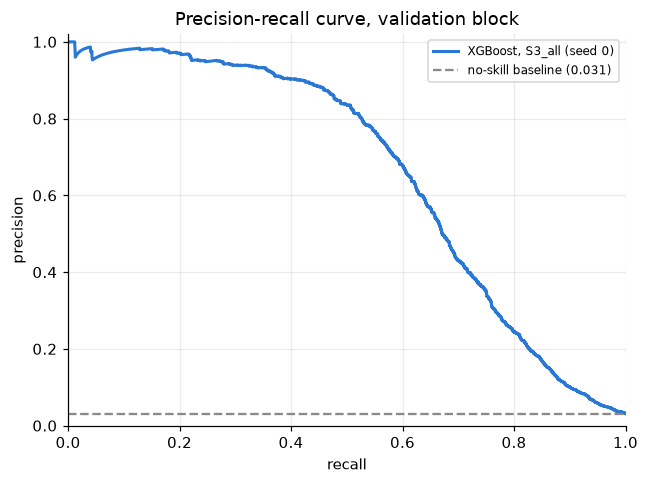

In [15]:
p, r, _ = precision_recall_curve(y[val_idx], final_scores[0])
base_rate = y[val_idx].mean()
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(r, p, color=COLORS[0], lw=2, label=f"XGBoost, {BEST_SET} (seed 0)")
ax.axhline(base_rate, color=GREY, ls="--", lw=1.5, label=f"no-skill baseline ({base_rate:.3f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall curve, validation block")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 10. What the model relies on

Two views on the final seed-0 model:

- **Gain:** how much each feature improved the training objective across all the splits that used it.
- **SHAP (mean |contribution|):** on a random 20,000-row sample of the validation block, the average size of
  each feature's push on the predicted log-odds. Computed with XGBoost's built-in TreeSHAP (`pred_contribs`).

Engineered features are marked so it's easy to see whether the model actually uses them.

In [16]:
gain = pd.Series(final_booster.get_score(importance_type="gain")).sort_values(ascending=False)

rng = np.random.default_rng(0)
sample = np.sort(rng.choice(val_idx, size=min(20_000, len(val_idx)), replace=False))
d = xgb.DMatrix(full[cols].iloc[sample], enable_categorical=True)
contrib = final_booster.predict(d, pred_contribs=True, iteration_range=(0, final_booster.best_iteration + 1))
shap_mean = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=cols).sort_values(ascending=False)

def kind(c):
    return "engineered" if c.startswith("fe_") else "raw"

importance = pd.DataFrame({"gain": gain, "mean_abs_shap": shap_mean}).fillna(0)
importance["kind"] = [kind(c) for c in importance.index]
importance["gain_rank"] = importance["gain"].rank(ascending=False).astype(int)
importance["shap_rank"] = importance["mean_abs_shap"].rank(ascending=False).astype(int)
top = importance.sort_values("mean_abs_shap", ascending=False).head(25)
print(f"engineered features in the top 25 by SHAP: {(top['kind'] == 'engineered').sum()}")
top.round(4)

engineered features in the top 25 by SHAP: 12


,gain,mean_abs_shap,kind,gain_rank,shap_rank
C13,30.0054,0.3787,raw,42,1
TransactionAmt,11.9439,0.3661,raw,166,2
fe_freq_addr1,10.2357,0.3402,engineered,200,3
card1,10.1224,0.3079,raw,202,4
fe_freq_card1,10.1031,0.3065,engineered,203,5
P_emaildomain,17.5888,0.2995,raw,85,6
card2,9.9032,0.2860,raw,207,7
C1,42.4608,0.2662,raw,22,8
fe_D1n,17.5653,0.2597,engineered,86,9
fe_card4_card6,20.0330,0.2585,engineered,68,10


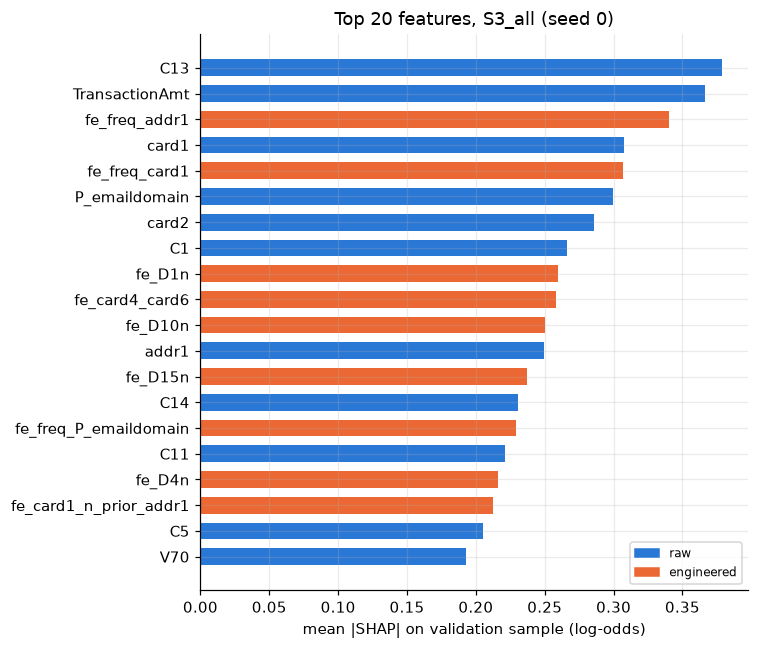

In [17]:
top20 = importance.sort_values("mean_abs_shap", ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
colors = [COLORS[1] if k == "engineered" else COLORS[0] for k in top20["kind"]]
ax.barh(top20.index, top20["mean_abs_shap"], color=colors, height=0.65)
ax.set_xlabel("mean |SHAP| on validation sample (log-odds)")
ax.set_title(f"Top 20 features, {BEST_SET} (seed 0)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLORS[0], label="raw"), Patch(color=COLORS[1], label="engineered")],
          fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

## 11. Summary

All numbers below are read from `results/log.csv`.

In [18]:
print("Ladder (time CV, all seeds):")
display(cv_table(LADDER)[["pr_auc_mean", "pr_auc_std", "auroc_mean", "recall_top1pct_mean", "n_runs"]])
if len(ablation):
    print("Leave-one-family-out (seed 0), change vs S3_all:")
    display(ablation[["change_mean", "change_std", "folds_worse"]])
print("V-column variants (seed 0):")
display(cv_table(V_SETS, seeds=[0])[["pr_auc_mean", "pr_auc_std", "n_runs"]])
print(f"Final model on the validation block ({BEST_SET}, config {BEST_CONFIG}, mean ± std over seeds):")
display(val_table)

Ladder (time CV, all seeds):


,pr_auc_mean,pr_auc_std,auroc_mean,recall_top1pct_mean,n_runs
feature_set,,,,,
S0_raw,0.5361,0.0323,0.8814,0.2398,12
S1_row,0.5559,0.0427,0.8799,0.2425,12
S2_history,0.5602,0.0340,0.8831,0.2433,12
S3_all,0.5712,0.0331,0.8865,0.2443,12


Leave-one-family-out (seed 0), change vs S3_all:


,change_mean,change_std,folds_worse
family removed,,,
d_norm,-0.0106,0.0130,2
frequency,-0.0015,0.0084,2
identity,0.0002,0.0169,3
geo_card,0.0004,0.0069,1
time,0.0012,0.0126,3
missing,0.0018,0.0113,3
velocity,0.0047,0.0303,3
novelty,0.0066,0.0238,3
amount,0.0100,0.0271,2


V-column variants (seed 0):


,pr_auc_mean,pr_auc_std,n_runs
feature_set,,,
S3_noV,0.5578,0.0366,4
S3_all,0.5662,0.0439,4
S3_allV,0.5642,0.0372,4


Final model on the validation block (S3_all, config tune16, mean ± std over seeds):


pr_auc           auroc         precision          recall         recall_top1pct           n_rows     
             mean     std    mean     std      mean     std    mean     std           mean     std     mean  std
subset                                                                                                          
all        0.6599  0.0009  0.9262  0.0013    0.7402  0.0172  0.5669  0.0049         0.3006  0.0012  59054.0  0.0
returning  0.8593  0.0013  0.9799  0.0002    0.9127  0.0078  0.7396  0.0086         0.4411  0.0009  28685.0  0.0
new        0.5521  0.0021  0.8738  0.0022    0.6408  0.0217  0.4756  0.0030         0.2312  0.0014  30369.0  0.0

Things to write up once the numbers are in:

- **Ladder:** which step gives the biggest gain, and is it larger than the fold spread? The step from `S1_row` to
  `S2_history` is the "user profile" question in RQ3.
- **Ablation:** which families matter, and which could be dropped without loss.
- **V columns:** does pruning cost anything, and how much do the masked V columns add over the rest?
- **CV vs validation:** if the validation PR-AUC is clearly lower than CV, some of the tuning gains were luck,
  or the later period is harder (check the fraud rates in the split table).
- **Returning vs new:** how much of the performance comes from customers the model has already seen.
- **Importance:** whether the engineered features show up near the top, and whether that matches the ablation.